# Module 03 – Machine Learning

This notebook completes **PS4 delivery-time regression** and **PS5 late-delivery classification** using the prepared Module 02 dataset. It uses only the approved order-placement inputs, keeps the 30-minute analytical SLA, and leaves PS6–PS8 out of scope. The saved pipelines include the same feature engineering and preprocessing used here so they can be loaded by a future Streamlit application.

## 1. Project Overview

We compare simple baselines with several machine-learning models. All decisions use chronological training and validation periods; the latest period is reserved for final testing. This is an analytical exercise on food-delivery data, so results should not be assumed to generalize to every quick-commerce operation.

## 2. Imports and Configuration

Use reproducible settings and project-relative paths. XGBoost is optional and is included only when the package is installed.

In [1]:
from pathlib import Path
import importlib.util
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.calibration import calibration_curve
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, ConfusionMatrixDisplay, confusion_matrix, f1_score,
    mean_absolute_error, mean_squared_error, precision_score, r2_score,
    recall_score, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
SLA_MINUTES = 30
FEATURES = ["Order_Date", "Time_Orderd", "Type_of_order", "City", "Festival", "distance_km"]
REGRESSION_TARGET = "delivery_time"
CLASSIFICATION_TARGET = "is_late"

ROOT = next(
    (candidate for candidate in (Path.cwd(), Path.cwd().parent)
     if (candidate / "data" / "model_ready_data.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Cannot locate data/model_ready_data.csv relative to the notebook.")
DATA_PATH = ROOT / "data" / "model_ready_data.csv"
FEATURE_REPORT_PATH = ROOT / "outputs" / "ps2" / "feature_availability_report.csv"
SUMMARY_PATH = ROOT / "outputs" / "ps2" / "delay_lens_summary.json"
MODEL_DIR = ROOT / "models"
ML_DIR = ROOT / "outputs" / "ml"
COMPARISON_DIR = ML_DIR / "model_comparison"
IMPORTANCE_DIR = ML_DIR / "feature_importance"
PLOT_DIR = ML_DIR / "plots"
for directory in (MODEL_DIR, ML_DIR, COMPARISON_DIR, IMPORTANCE_DIR, PLOT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
print("Project root:", ROOT)
print("SLA_MINUTES:", SLA_MINUTES)
print("XGBoost available:", bool(importlib.util.find_spec("xgboost")))

Project root: C:\Users\javed\Desktop\calibo\Manthan
SLA_MINUTES: 30
XGBoost available: False


## 3. Dataset Loading and Validation

Load the existing model-ready data and Module 02’s authoritative feature report. Do not repeat PS1 cleaning. Fail early if the data, SLA, approved features, or target labels disagree with their existing reports.

In [2]:
try:
    data = pd.read_csv(DATA_PATH)
    feature_report = pd.read_csv(FEATURE_REPORT_PATH)
    with SUMMARY_PATH.open(encoding="utf-8") as file:
        delay_summary = json.load(file)
except (OSError, pd.errors.ParserError, UnicodeError, json.JSONDecodeError) as exc:
    raise RuntimeError(f"Unable to load a required Module 02 input: {exc}") from exc

if delay_summary["sla"]["minutes"] != SLA_MINUTES:
    raise AssertionError("Module 02 and Module 03 must use the same 30-minute analytical SLA.")
if len(data) != 45593:
    raise AssertionError(f"Unexpected model-ready record count: {len(data):,}")
if data["ID"].astype("string").str.strip().duplicated().any():
    raise AssertionError("Order IDs must be unique before chronological partitioning.")

print("Model-ready shape:", data.shape)
print("Order dates:", data["Order_Date"].min(), "to", data["Order_Date"].max())
print("Missing approved inputs:", data[FEATURES].isna().sum().to_dict())
print("Target missingness:", data[[REGRESSION_TARGET, CLASSIFICATION_TARGET]].isna().sum().to_dict())
display(data[FEATURES + [REGRESSION_TARGET, CLASSIFICATION_TARGET]].head())

Model-ready shape: (45593, 52)
Order dates: 2022-02-11 to 2022-04-06
Missing approved inputs: {'Order_Date': 0, 'Time_Orderd': 1731, 'Type_of_order': 0, 'City': 0, 'Festival': 0, 'distance_km': 4071}
Target missingness: {'delivery_time': 0, 'is_late': 0}


,Order_Date,Time_Orderd,Type_of_order,City,Festival,distance_km,delivery_time,is_late
0,2022-03-19,11:30:00,Snack,Urban,No,3.025153,24,0
1,2022-03-25,19:45:00,Snack,Metropolitan,No,20.183558,33,1
2,2022-03-19,08:30:00,Drinks,Urban,No,1.552760,26,0
3,2022-04-05,18:00:00,Buffet,Metropolitan,No,7.790412,21,0
4,2022-03-26,13:30:00,Snack,Metropolitan,No,6.210147,30,0


## 4. Target and Feature Selection

The regression target is actual delivery duration in minutes. The classification target is Module 02’s nullable 30-minute analytical late label. Only the six approved order-placement columns are model inputs.

In [3]:
reported_regression_features = feature_report.loc[
    feature_report["in_regression_features"].astype(bool), "column"
].tolist()
reported_classification_features = feature_report.loc[
    feature_report["in_classification_features"].astype(bool), "column"
].tolist()
if set(reported_regression_features) != set(FEATURES) or set(reported_classification_features) != set(FEATURES):
    raise AssertionError(
        "Approved features do not match Module 02's authoritative availability report."
    )
if delay_summary["features"]["regression"] != FEATURES:
    raise AssertionError("Regression feature summary differs from the requested approved list.")
if delay_summary["features"]["classification"] != FEATURES:
    raise AssertionError("Classification feature summary differs from the requested approved list.")
REGRESSION_FEATURES = delay_summary["features"]["regression"].copy()
CLASSIFICATION_FEATURES = delay_summary["features"]["classification"].copy()

X_all = data.loc[:, FEATURES].copy()
y_regression_all = pd.to_numeric(data[REGRESSION_TARGET], errors="coerce")
y_classification_all = pd.to_numeric(data[CLASSIFICATION_TARGET], errors="coerce")
modeling_rows = y_regression_all.notna() & y_classification_all.notna()
excluded_missing_targets = int((~modeling_rows).sum())
X = X_all.loc[modeling_rows].copy()
y_regression = y_regression_all.loc[modeling_rows].astype(float)
y_classification = y_classification_all.loc[modeling_rows].astype("int8")

expected_labels = (y_regression > SLA_MINUTES).astype("int8")
if not y_classification.equals(expected_labels.rename(CLASSIFICATION_TARGET)):
    raise AssertionError("is_late does not match delivery_time > SLA_MINUTES.")
if not y_classification.isin([0, 1]).all():
    raise AssertionError("Classification targets must contain only 0 and 1.")

print("Approved feature list:", FEATURES)
print("Rows eligible for supervised learning:", len(X), "| missing-target rows excluded:", excluded_missing_targets)
print("Regression target range:", y_regression.min(), "to", y_regression.max(), "minutes")
print("Classification class counts:", y_classification.value_counts().sort_index().to_dict())

Approved feature list: ['Order_Date', 'Time_Orderd', 'Type_of_order', 'City', 'Festival', 'distance_km']
Rows eligible for supervised learning: 45593 | missing-target rows excluded: 0
Regression target range: 10.0 to 54.0 minutes
Classification class counts: {0: 31987, 1: 13606}


## 5. Data Leakage Prevention

Actual delivery outcomes, pickup times, weather, traffic, rider/vehicle details, identifiers, and audit flags are not passed to either estimator. Module 02’s feature availability report is authoritative; PS1’s preprocessing illustration is not used to select Module 03 inputs.

In [4]:
FORBIDDEN_INPUTS = {
    "Time_taken(min)", "delivery_time", "is_late", "Time_Order_picked",
    "Weatherconditions", "Road_traffic_density", "Delivery_person_ID",
    "Delivery_person_Age", "Delivery_person_Ratings", "Vehicle_condition",
    "Type_of_vehicle", "multiple_deliveries", "ID",
}
assert set(FEATURES).isdisjoint(FORBIDDEN_INPUTS)
assert set(FEATURES) == set(reported_regression_features) == set(reported_classification_features)
assert all(column in data.columns for column in FEATURES)
assert REGRESSION_TARGET not in FEATURES and CLASSIFICATION_TARGET not in FEATURES
assert "Time_Order_picked" not in FEATURES

leakage_check = pd.DataFrame(
    [{"column": name, "used_as_input": name in FEATURES} for name in sorted(FORBIDDEN_INPUTS)]
)
display(leakage_check)
print("Leakage checks passed for both tasks.")

,column,used_as_input
0,Delivery_person_Age,False
1,Delivery_person_ID,False
2,Delivery_person_Ratings,False
3,ID,False
4,Road_traffic_density,False
5,Time_Order_picked,False
6,Time_taken(min),False
7,Type_of_vehicle,False
8,Vehicle_condition,False
9,Weatherconditions,False


Leakage checks passed for both tasks.


## 6. Feature Engineering

Convert order date and order time into numeric calendar and clock features. Missing timestamps remain missing in derived values and get explicit missingness indicators. Distance and derived time numbers are imputed only inside a preprocessing pipeline fit on training data.

In [5]:
from src.feature_engineering import (
    CATEGORICAL_FEATURES,
    ENGINEERED_FEATURES,
    ENGINEERED_NUMERIC_FEATURES,
    engineer_features,
)

missing_input_sample = X.loc[
    X["Time_Orderd"].isna() | X["distance_km"].isna()
].head(8)
engineered_preview = engineer_features(missing_input_sample)
assert engineered_preview.columns.tolist() == ENGINEERED_FEATURES
assert engineered_preview["order_time_missing"].eq(1).any()
assert engineered_preview["distance_km"].isna().any()
print("Engineered features:", ENGINEERED_FEATURES)
display(engineered_preview.head())

Engineered features: ['order_year', 'order_month', 'order_day', 'order_dayofweek', 'order_dayofyear', 'order_hour', 'order_minute', 'order_hour_sin', 'order_hour_cos', 'order_date_missing', 'order_time_missing', 'distance_km', 'Type_of_order', 'City', 'Festival']


,order_year,order_month,order_day,order_dayofweek,order_dayofyear,order_hour,order_minute,order_hour_sin,order_hour_cos,order_date_missing,order_time_missing,distance_km,Type_of_order,City,Festival
33,2022.0,3.0,8.0,1.0,67.0,21.0,35.0,-0.591310,0.806445,0,0,NaN,Snack,Urban,No
42,2022.0,4.0,6.0,2.0,96.0,NaN,NaN,NaN,NaN,0,1,12.236741,Drinks,Metropolitan,No
52,2022.0,2.0,13.0,6.0,44.0,22.0,10.0,-0.461749,0.887011,0,0,NaN,Snack,Metropolitan,No
57,2022.0,3.0,2.0,2.0,61.0,20.0,35.0,-0.779884,0.625923,0,0,NaN,Snack,Semi-Urban,No
59,2022.0,3.0,13.0,6.0,72.0,20.0,15.0,-0.831470,0.555570,0,0,NaN,Snack,Metropolitan,No


## 7. Chronological Train/Validation/Test Split

Split on unique order dates—not rows—so a date and its orders cannot appear in multiple partitions. The first 70% of distinct dates form training, the next 15% validation, and the final 15% test. Missing `Order_Date` values cannot be placed chronologically, so the notebook reports and rejects them rather than assigning invented dates. The current dataset has no missing order dates.

In [6]:
order_dates = pd.to_datetime(X["Order_Date"], errors="coerce").dt.normalize()
missing_order_dates = int(order_dates.isna().sum())
if missing_order_dates:
    raise ValueError(
        f"{missing_order_dates} eligible rows lack Order_Date; chronological evaluation "
        "cannot safely place them. Preserve them for non-chronological inference, but do not guess a date."
    )

unique_dates = np.sort(order_dates.unique())
if len(unique_dates) < 10:
    raise ValueError("Too few unique order dates for a meaningful chronological split.")
train_date_end = int(np.floor(len(unique_dates) * 0.70))
validation_date_end = int(np.floor(len(unique_dates) * 0.85))
train_date_end = max(1, train_date_end)
validation_date_end = max(train_date_end + 1, validation_date_end)
validation_date_end = min(validation_date_end, len(unique_dates) - 1)
train_dates = unique_dates[:train_date_end]
validation_dates = unique_dates[train_date_end:validation_date_end]
test_dates = unique_dates[validation_date_end:]

train_mask = order_dates.isin(train_dates)
validation_mask = order_dates.isin(validation_dates)
test_mask = order_dates.isin(test_dates)
if (train_mask.astype(int) + validation_mask.astype(int) + test_mask.astype(int)).ne(1).any():
    raise AssertionError("Every supervised row must belong to exactly one chronological partition.")

X_train, X_validation, X_test = X.loc[train_mask], X.loc[validation_mask], X.loc[test_mask]
y_reg_train = y_regression.loc[train_mask]
y_reg_validation = y_regression.loc[validation_mask]
y_reg_test = y_regression.loc[test_mask]
y_clf_train = y_classification.loc[train_mask]
y_clf_validation = y_classification.loc[validation_mask]
y_clf_test = y_classification.loc[test_mask]

date_partitions = {
    "train": set(pd.to_datetime(X_train["Order_Date"]).dt.normalize()),
    "validation": set(pd.to_datetime(X_validation["Order_Date"]).dt.normalize()),
    "test": set(pd.to_datetime(X_test["Order_Date"]).dt.normalize()),
}
assert date_partitions["train"].isdisjoint(date_partitions["validation"])
assert date_partitions["train"].isdisjoint(date_partitions["test"])
assert date_partitions["validation"].isdisjoint(date_partitions["test"])
assert max(date_partitions["train"]) < min(date_partitions["validation"])
assert max(date_partitions["validation"]) < min(date_partitions["test"])
id_partitions = [set(part["ID"].astype("string")) for part in (
    data.loc[modeling_rows].loc[train_mask],
    data.loc[modeling_rows].loc[validation_mask],
    data.loc[modeling_rows].loc[test_mask],
)]
assert id_partitions[0].isdisjoint(id_partitions[1])
assert id_partitions[0].isdisjoint(id_partitions[2])
assert id_partitions[1].isdisjoint(id_partitions[2])

split_summary = pd.DataFrame(
    [
        {"partition": name, "rows": len(part), "first_date": min(date_partitions[name]),
         "last_date": max(date_partitions[name]), "distinct_dates": len(date_partitions[name])}
        for name, part in [("train", X_train), ("validation", X_validation), ("test", X_test)]
    ]
)
display(split_summary)
print("Partition target class counts:",
      {name: labels.value_counts().sort_index().to_dict() for name, labels in [
          ("train", y_clf_train), ("validation", y_clf_validation), ("test", y_clf_test)
      ]})

,partition,rows,first_date,last_date,distinct_dates
0,train,30739,2022-02-11,2022-03-23,30
1,validation,7525,2022-03-24,2022-03-30,7
2,test,7329,2022-03-31,2022-04-06,7


Partition target class counts: {'train': {0: 21486, 1: 9253}, 'validation': {0: 5413, 1: 2112}, 'test': {0: 5088, 1: 2241}}


## 8. Regression Preprocessing

Use one reusable preprocessing pipeline for every regression candidate. Numeric values—including missing distance and missing order time—use the training-partition median. Categorical fields use `Unknown` plus one-hot encoding. The feature-engineering step is part of each saved end-to-end pipeline.

In [7]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric = Pipeline(numeric_steps)
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(
        [
            ("numeric", numeric, ENGINEERED_NUMERIC_FEATURES),
            ("categorical", categorical, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
    )


def make_pipeline(estimator, scale_numeric=False):
    return Pipeline(
        [
            ("feature_engineering", FunctionTransformer(engineer_features, validate=False)),
            ("preprocessing", make_preprocessor(scale_numeric=scale_numeric)),
            ("model", estimator),
        ]
    )


print("Numeric inputs:", ENGINEERED_NUMERIC_FEATURES)
print("Categorical inputs:", CATEGORICAL_FEATURES)

Numeric inputs: ['order_year', 'order_month', 'order_day', 'order_dayofweek', 'order_dayofyear', 'order_hour', 'order_minute', 'order_hour_sin', 'order_hour_cos', 'order_date_missing', 'order_time_missing', 'distance_km']
Categorical inputs: ['Type_of_order', 'City', 'Festival']


## 9. PS4 – Regression Models

Compare a mean baseline, Ridge regression, and a random-forest regressor. XGBoost is added only if installed. Every candidate fits its own preprocessing using `X_train` only.

In [8]:
regression_estimators = {
    "DummyRegressor": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=2.0),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=140, min_samples_leaf=2, max_features=0.8,
        n_jobs=1, random_state=RANDOM_STATE,
    ),
}
if importlib.util.find_spec("xgboost"):
    from xgboost import XGBRegressor
    regression_estimators["XGBoostRegressor"] = XGBRegressor(
        n_estimators=180, max_depth=5, learning_rate=0.06,
        subsample=0.85, colsample_bytree=0.85, objective="reg:squarederror",
        n_jobs=1, random_state=RANDOM_STATE,
    )


def regression_metrics(y_true, predictions):
    return {
        "mae": float(mean_absolute_error(y_true, predictions)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, predictions))),
        "r2": float(r2_score(y_true, predictions)),
    }


regression_pipelines = {}
regression_validation_rows = []
for name, estimator in regression_estimators.items():
    pipeline = make_pipeline(estimator)
    start = time.perf_counter()
    pipeline.fit(X_train, y_reg_train)
    elapsed = time.perf_counter() - start
    predictions = pipeline.predict(X_validation)
    regression_pipelines[name] = pipeline
    regression_validation_rows.append({
        "model": name,
        **regression_metrics(y_reg_validation, predictions),
        "fit_seconds": round(elapsed, 2),
    })
    print(f"Fitted {name} in {elapsed:.1f} seconds.")

Fitted DummyRegressor in 0.5 seconds.


Fitted Ridge in 0.5 seconds.


Fitted RandomForestRegressor in 11.6 seconds.


## 10. Regression Model Comparison

Compare validation metrics and choose the model with the lowest validation MAE. The test period is not used for this choice.

In [9]:
regression_comparison = pd.DataFrame(regression_validation_rows).sort_values(
    "mae", ascending=True
).reset_index(drop=True)
best_regression_name = regression_comparison.loc[0, "model"]
best_regression_pipeline = regression_pipelines[best_regression_name]
print("Regression selection by validation MAE:", best_regression_name)
display(regression_comparison)

Regression selection by validation MAE: RandomForestRegressor


,model,mae,rmse,r2,fit_seconds
0,RandomForestRegressor,6.251865,7.847448,0.293675,11.65
1,Ridge,6.488171,8.066093,0.253768,0.50
2,DummyRegressor,7.601160,9.358807,-0.004589,0.45


## 11. Regression Evaluation and Feature Importance

Evaluate the selected regressor once on the untouched test period. Save actual-versus-predicted and residual plots. Permutation importance is computed on test inputs only for post-selection interpretation; it does not change model selection.

Selected model (chosen by validation MAE only): RandomForestRegressor
Validation metrics: {'mae': 6.2518650109474985, 'rmse': 7.847447988521355, 'r2': 0.2936752020972535}
Held-out test comparison (reporting only):


,model,mae,rmse,r2
0,RandomForestRegressor,6.272237,7.861580,0.303062
1,Ridge,6.570360,8.168295,0.247620
2,DummyRegressor,7.606012,9.418307,-0.000277


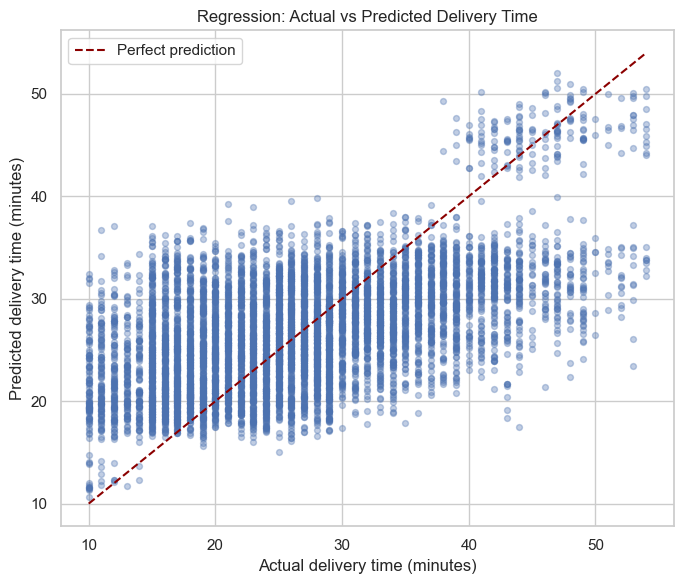

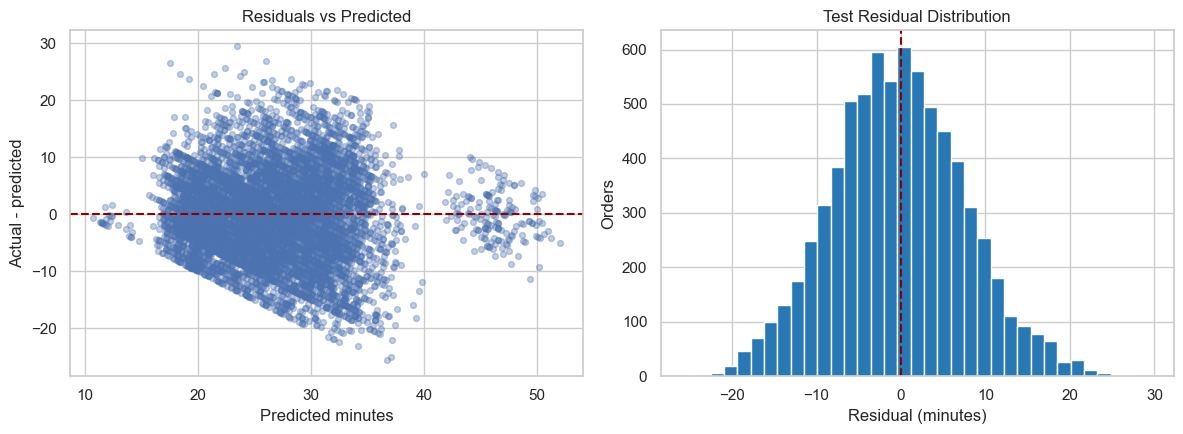

,feature,importance_mean,importance_std
1,Time_Orderd,1.159199,0.067667
5,distance_km,0.593097,0.015130
4,Festival,0.415347,0.022036
3,City,0.270944,0.044712
2,Type_of_order,0.029931,0.007233
0,Order_Date,0.019261,0.013643


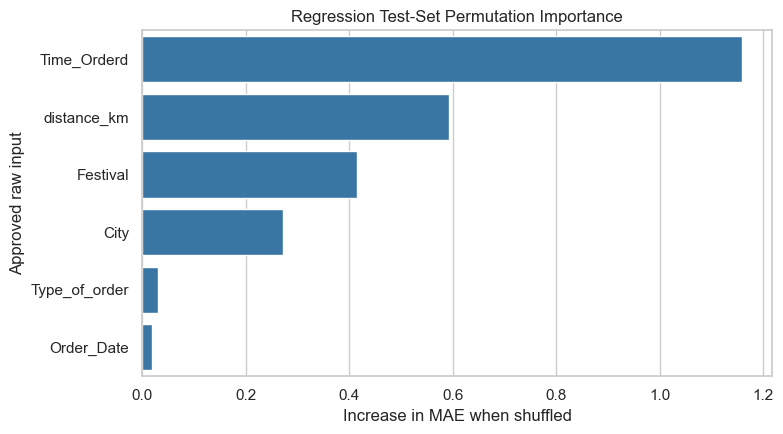

In [10]:
regression_validation_predictions = best_regression_pipeline.predict(X_validation)
regression_validation_metrics = regression_metrics(
    y_reg_validation, regression_validation_predictions
)

# Each candidate is evaluated once on the held-out test partition; these results
# are reported only and do not affect selection or tuning.
regression_test_predictions_by_model = {}
regression_test_rows = []
for name, pipeline in regression_pipelines.items():
    test_predictions = pipeline.predict(X_test)
    regression_test_predictions_by_model[name] = test_predictions
    regression_test_rows.append({
        "model": name,
        **regression_metrics(y_reg_test, test_predictions),
    })
regression_test_comparison = pd.DataFrame(regression_test_rows).sort_values(
    "mae", ascending=True
).reset_index(drop=True)
regression_test_predictions = regression_test_predictions_by_model[best_regression_name]
regression_test_metrics = regression_metrics(y_reg_test, regression_test_predictions)
print("Selected model (chosen by validation MAE only):", best_regression_name)
print("Validation metrics:", regression_validation_metrics)
print("Held-out test comparison (reporting only):")
display(regression_test_comparison)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_reg_test, regression_test_predictions, alpha=0.35, s=18)
limits = [min(y_reg_test.min(), regression_test_predictions.min()),
          max(y_reg_test.max(), regression_test_predictions.max())]
ax.plot(limits, limits, "--", color="darkred", label="Perfect prediction")
ax.set(title="Regression: Actual vs Predicted Delivery Time",
       xlabel="Actual delivery time (minutes)", ylabel="Predicted delivery time (minutes)")
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "regression_actual_vs_predicted.png", dpi=150)
plt.show()
plt.close(fig)

regression_residuals = y_reg_test.to_numpy() - regression_test_predictions
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(regression_test_predictions, regression_residuals, alpha=0.35, s=18)
axes[0].axhline(0, color="darkred", linestyle="--")
axes[0].set(title="Residuals vs Predicted", xlabel="Predicted minutes", ylabel="Actual - predicted")
axes[1].hist(regression_residuals, bins=35, color="#2878B5", edgecolor="white")
axes[1].axvline(0, color="darkred", linestyle="--")
axes[1].set(title="Test Residual Distribution", xlabel="Residual (minutes)", ylabel="Orders")
fig.tight_layout()
fig.savefig(PLOT_DIR / "regression_residual_analysis.png", dpi=150)
plt.show()
plt.close(fig)

importance_rows = min(2500, len(X_test))
regression_permutation = permutation_importance(
    best_regression_pipeline,
    X_test.sample(importance_rows, random_state=RANDOM_STATE),
    y_reg_test.loc[X_test.sample(importance_rows, random_state=RANDOM_STATE).index],
    scoring="neg_mean_absolute_error",
    n_repeats=4,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
regression_importance = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": regression_permutation.importances_mean,
    "importance_std": regression_permutation.importances_std,
}).sort_values("importance_mean", ascending=False)
display(regression_importance)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=regression_importance, x="importance_mean", y="feature", color="#2878B5", ax=ax)
ax.set(title="Regression Test-Set Permutation Importance",
       xlabel="Increase in MAE when shuffled", ylabel="Approved raw input")
fig.tight_layout()
fig.savefig(IMPORTANCE_DIR / "regression_permutation_importance.png", dpi=150)
plt.show()
plt.close(fig)

## 12. Classification Preprocessing

Classification uses the same shared feature engineering and train-fitted imputers/encoder. Class weights are used for trainable models to account for the observed late/on-time imbalance; validation and test samples are not resampled.

In [11]:
class_counts = y_clf_train.value_counts().sort_index()
if set(class_counts.index) != {0, 1}:
    raise ValueError("Training period must contain both on-time and late labels.")
class_weight_ratio = float(class_counts.loc[0] / class_counts.loc[1])
print("Training class counts:", class_counts.to_dict())
print("Late class-weight ratio (on-time / late):", round(class_weight_ratio, 3))

Training class counts: {0: 21486, 1: 9253}
Late class-weight ratio (on-time / late): 2.322


## 13. PS5 – Classification Models

Compare a prior-probability baseline, balanced logistic regression, and a balanced random forest. XGBoost is optional and is included only when installed. Pipelines fit preprocessing and estimators on training rows only.

In [12]:
classification_estimators = {
    "DummyClassifier": DummyClassifier(strategy="prior"),
    "LogisticRegression": LogisticRegression(
        max_iter=5000, class_weight="balanced", solver="lbfgs",
        random_state=RANDOM_STATE,
    ),
    "RandomForestClassifier": RandomForestClassifier(
        n_estimators=140, min_samples_leaf=2, max_features=0.8,
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE,
    ),
}
if importlib.util.find_spec("xgboost"):
    from xgboost import XGBClassifier
    classification_estimators["XGBoostClassifier"] = XGBClassifier(
        n_estimators=180, max_depth=5, learning_rate=0.06,
        subsample=0.85, colsample_bytree=0.85,
        scale_pos_weight=class_weight_ratio,
        eval_metric="logloss", n_jobs=1, random_state=RANDOM_STATE,
    )


def classification_metrics(y_true, probabilities, threshold=0.5):
    predictions = (np.asarray(probabilities) >= threshold).astype("int8")
    return {
        "threshold": float(threshold),
        "precision": float(precision_score(y_true, predictions, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, probabilities)),
        "pr_auc": float(average_precision_score(y_true, probabilities)),
        "accuracy": float(accuracy_score(y_true, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, predictions)),
        "confusion_matrix": confusion_matrix(y_true, predictions, labels=[0, 1]).tolist(),
    }


classification_pipelines = {}
classification_validation_rows = []
validation_probabilities = {}
for name, estimator in classification_estimators.items():
    pipeline = make_pipeline(
        estimator, scale_numeric=(name == "LogisticRegression")
    )
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as fit_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        pipeline.fit(X_train, y_clf_train)
    elapsed = time.perf_counter() - start
    convergence_warnings = [
        warning for warning in fit_warnings
        if issubclass(warning.category, ConvergenceWarning)
    ]
    if convergence_warnings:
        raise RuntimeError(
            f"{name} did not converge: {convergence_warnings[0].message}"
        )
    if name == "LogisticRegression":
        fitted_logistic = pipeline.named_steps["model"]
        if np.max(fitted_logistic.n_iter_) >= fitted_logistic.max_iter:
            raise RuntimeError("Logistic Regression reached max_iter without convergence.")
        print("Logistic Regression converged in", int(np.max(fitted_logistic.n_iter_)), "iterations.")
    probabilities = pipeline.predict_proba(X_validation)[:, 1]
    metrics = classification_metrics(y_clf_validation, probabilities, threshold=0.5)
    classification_pipelines[name] = pipeline
    validation_probabilities[name] = probabilities
    classification_validation_rows.append({"model": name, **metrics, "fit_seconds": round(elapsed, 2)})
    print(f"Fitted {name} in {elapsed:.1f} seconds.")

Fitted DummyClassifier in 0.5 seconds.


Logistic Regression converged in 47 iterations.
Fitted LogisticRegression in 0.6 seconds.


Fitted RandomForestClassifier in 2.1 seconds.


## 14. Classification Model Comparison

Compare validation precision, recall, F1, ROC-AUC, PR-AUC, accuracy, and balanced accuracy at the conventional 0.5 threshold. Select the final classifier by validation PR-AUC, which is informative under class imbalance. Test results are not used in this decision.

In [13]:
classification_comparison = pd.DataFrame(classification_validation_rows).sort_values(
    ["pr_auc", "roc_auc"], ascending=False
).reset_index(drop=True)
best_classification_name = classification_comparison.loc[0, "model"]
best_classification_pipeline = classification_pipelines[best_classification_name]
best_validation_probabilities = validation_probabilities[best_classification_name]
print("Classification selection by validation PR-AUC:", best_classification_name)
display(classification_comparison.drop(columns="confusion_matrix"))

Classification selection by validation PR-AUC: RandomForestClassifier


,model,threshold,precision,recall,f1,roc_auc,pr_auc,accuracy,balanced_accuracy,fit_seconds
0,RandomForestClassifier,0.5,0.545687,0.506155,0.525178,0.778565,0.581686,0.743123,0.670868,2.14
1,LogisticRegression,0.5,0.434647,0.725852,0.543713,0.745827,0.552833,0.658073,0.678740,0.60
2,DummyClassifier,0.5,0.000000,0.000000,0.000000,0.500000,0.280664,0.719336,0.500000,0.51


## 15. Classification Threshold Selection

Choose a threshold for the selected classifier using validation scores only. The rule maximizes validation F1 over a documented threshold grid; ties prefer the higher threshold. A lower threshold generally catches more late orders (higher recall) but also increases false alerts and may reduce precision. Earlier identification can support operational checks or customer updates, but no business-cost data is available, so this is not a cost-optimal threshold. Report the default 0.5 result beside the selected threshold.

Selected validation-only risk-score threshold: 0.29
Validation at 0.5: {'threshold': 0.5, 'precision': 0.5456865747830526, 'recall': 0.506155303030303, 'f1': 0.5251780889216409, 'roc_auc': 0.77856522807047, 'pr_auc': 0.5816859018685079, 'accuracy': 0.7431229235880399, 'balanced_accuracy': 0.6708681558565519}
Validation at selected threshold: {'threshold': 0.29, 'precision': 0.4465863453815261, 'recall': 0.7897727272727273, 'f1': 0.5705489994869164, 'roc_auc': 0.77856522807047, 'pr_auc': 0.5816859018685079, 'accuracy': 0.666312292358804, 'balanced_accuracy': 0.703957119224762}


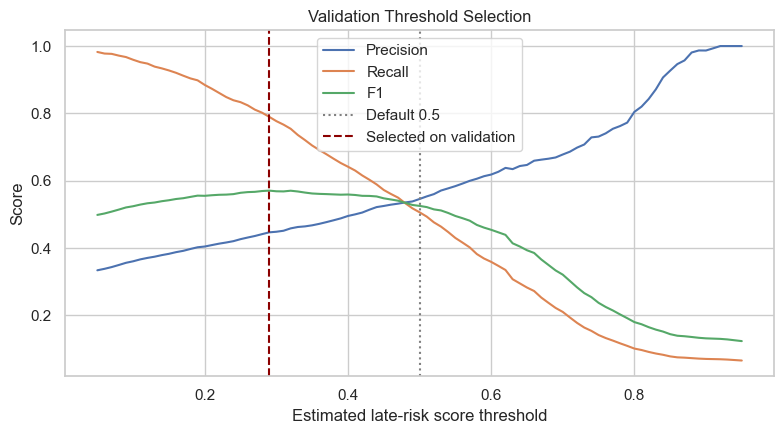

In [14]:
threshold_grid = np.linspace(0.05, 0.95, 91)
threshold_rows = []
for threshold in threshold_grid:
    metrics = classification_metrics(
        y_clf_validation, best_validation_probabilities, threshold=float(threshold)
    )
    threshold_rows.append({
        "threshold": float(threshold),
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
    })
threshold_results = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_results.sort_values(
    ["f1", "threshold"], ascending=[False, False]
).iloc[0]
selected_threshold = float(best_threshold_row["threshold"])
validation_metrics_at_05 = classification_metrics(
    y_clf_validation, best_validation_probabilities, threshold=0.5
)
validation_metrics_selected = classification_metrics(
    y_clf_validation, best_validation_probabilities, threshold=selected_threshold
)
print("Selected validation-only risk-score threshold:", selected_threshold)
print("Validation at 0.5:", {k: v for k, v in validation_metrics_at_05.items() if k != "confusion_matrix"})
print("Validation at selected threshold:", {k: v for k, v in validation_metrics_selected.items() if k != "confusion_matrix"})
threshold_results.to_csv(COMPARISON_DIR / "classification_threshold_sweep.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(threshold_results["threshold"], threshold_results["precision"], label="Precision")
ax.plot(threshold_results["threshold"], threshold_results["recall"], label="Recall")
ax.plot(threshold_results["threshold"], threshold_results["f1"], label="F1")
ax.axvline(0.5, color="gray", linestyle=":", label="Default 0.5")
ax.axvline(selected_threshold, color="darkred", linestyle="--", label="Selected on validation")
ax.set(title="Validation Threshold Selection", xlabel="Estimated late-risk score threshold", ylabel="Score")
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "classification_threshold_selection.png", dpi=150)
plt.show()
plt.close(fig)

## 16. Classification Evaluation and Feature Importance

Evaluate the selected classifier on the untouched test period using both the validation-selected threshold and 0.5 for comparison. The threshold is never adjusted using test outcomes. Check score calibration on this test period with Brier score and a reliability plot; no calibration transform is fitted. The model output is therefore an estimated late-delivery risk score, not a guaranteed probability. Save the confusion matrix, ROC and precision-recall curves, calibration plot, and test-set permutation importance.

Test calibration assessment: {'assessment_partition': 'test; diagnostic only, not used for fitting or selection', 'formal_calibration_applied': False, 'score_interpretation': 'Estimated late-delivery risk score; not a guaranteed probability.', 'test_late_prevalence': 0.3057715923045436, 'brier_score': 0.17102922575598598, 'training_prevalence_baseline_brier_score': 0.21229791990305388, 'expected_calibration_error_10_quantile_bins': 0.04597661596911695}


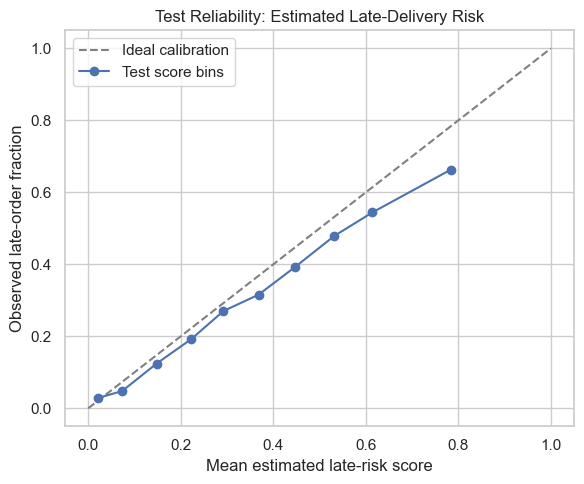

Selected model: RandomForestClassifier
Untouched test metrics at validation-selected threshold: {'threshold': 0.29, 'precision': 0.4606630380999505, 'recall': 0.8308790718429273, 'f1': 0.5927104886200859, 'roc_auc': 0.777742346043854, 'pr_auc': 0.599492005584682, 'accuracy': 0.6508391322144904, 'balanced_accuracy': 0.7012099761730359}
Untouched test metrics at 0.5: {'threshold': 0.5, 'precision': 0.5644171779141104, 'recall': 0.533690316822847, 'f1': 0.5486238532110091, 'roc_auc': 0.777742346043854, 'pr_auc': 0.599492005584682, 'accuracy': 0.7314776913630782, 'balanced_accuracy': 0.6761415420592223}


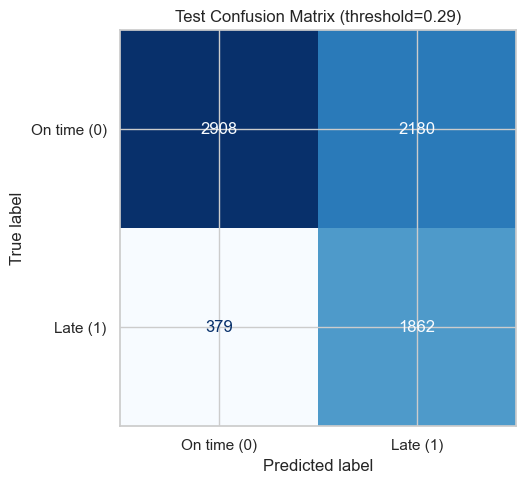

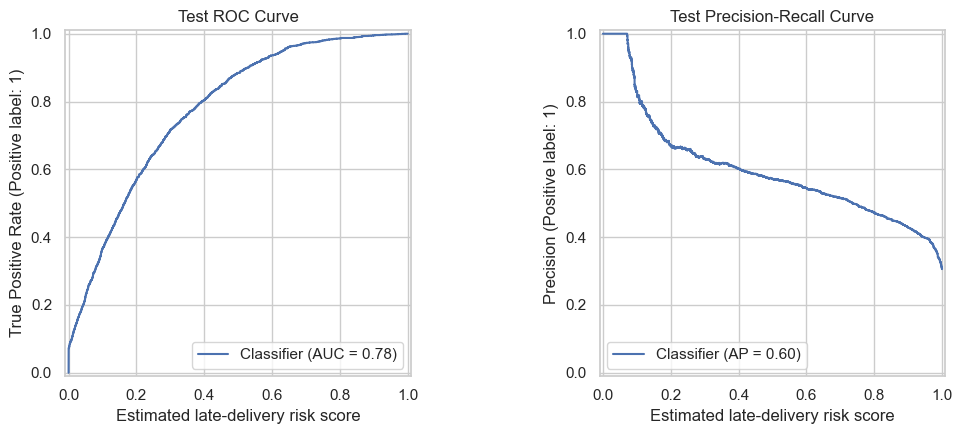

,feature,importance_mean,importance_std
1,Time_Orderd,0.125882,0.009013
4,Festival,0.072494,0.007968
5,distance_km,0.071114,0.008968
3,City,0.025610,0.007197
0,Order_Date,-0.001428,0.000770
2,Type_of_order,-0.003487,0.002761


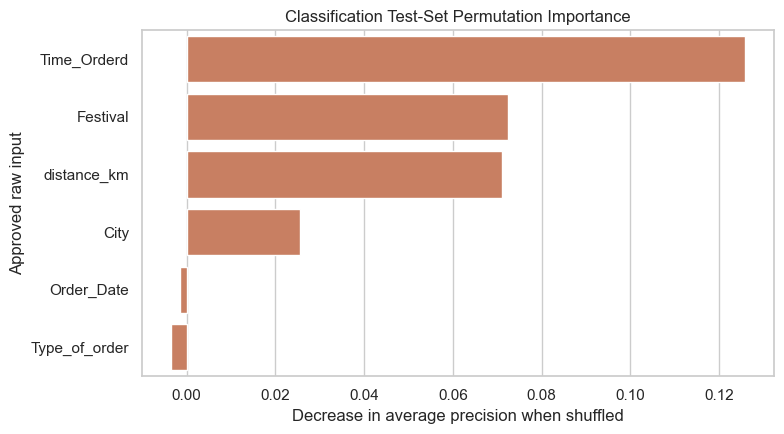

In [15]:
classification_test_probabilities = best_classification_pipeline.predict_proba(X_test)[:, 1]
classification_test_metrics = classification_metrics(
    y_clf_test, classification_test_probabilities, threshold=selected_threshold
)
classification_test_metrics_at_05 = classification_metrics(
    y_clf_test, classification_test_probabilities, threshold=0.5
)

# Calibration is assessed on the untouched test period only; no recalibration
# or threshold change is performed from these results.
test_prevalence = float(y_clf_test.mean())
calibration_baseline_score = float(y_clf_train.mean())
calibration_brier_score = float(
    brier_score_loss(y_clf_test, classification_test_probabilities)
)
baseline_brier_score = float(brier_score_loss(
    y_clf_test, np.full(len(y_clf_test), calibration_baseline_score)
))
calibration_true_fraction, calibration_mean_score = calibration_curve(
    y_clf_test, classification_test_probabilities, n_bins=10, strategy="quantile"
)
calibration_frame = pd.DataFrame({
    "actual_late": y_clf_test.to_numpy(),
    "estimated_late_risk_score": classification_test_probabilities,
})
calibration_frame["score_bin"] = pd.qcut(
    calibration_frame["estimated_late_risk_score"], q=10, duplicates="drop"
)
calibration_bins = calibration_frame.groupby("score_bin", observed=True).agg(
    mean_estimated_risk=("estimated_late_risk_score", "mean"),
    observed_late_fraction=("actual_late", "mean"),
    orders=("actual_late", "size"),
).reset_index(drop=True)
expected_calibration_error = float(np.average(
    np.abs(calibration_bins["mean_estimated_risk"] - calibration_bins["observed_late_fraction"]),
    weights=calibration_bins["orders"],
))
calibration_evaluation = {
    "assessment_partition": "test; diagnostic only, not used for fitting or selection",
    "formal_calibration_applied": False,
    "score_interpretation": "Estimated late-delivery risk score; not a guaranteed probability.",
    "test_late_prevalence": test_prevalence,
    "brier_score": calibration_brier_score,
    "training_prevalence_baseline_brier_score": baseline_brier_score,
    "expected_calibration_error_10_quantile_bins": expected_calibration_error,
    "calibration_bins": calibration_bins.to_dict(orient="records"),
}
print("Test calibration assessment:", {
    key: value for key, value in calibration_evaluation.items()
    if key != "calibration_bins"
})

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Ideal calibration")
ax.plot(calibration_mean_score, calibration_true_fraction, marker="o", label="Test score bins")
ax.set(title="Test Reliability: Estimated Late-Delivery Risk",
       xlabel="Mean estimated late-risk score", ylabel="Observed late-order fraction")
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "classification_calibration.png", dpi=150)
plt.show()
plt.close(fig)

print("Selected model:", best_classification_name)
print("Untouched test metrics at validation-selected threshold:",
      {k: v for k, v in classification_test_metrics.items() if k != "confusion_matrix"})
print("Untouched test metrics at 0.5:",
      {k: v for k, v in classification_test_metrics_at_05.items() if k != "confusion_matrix"})

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(
    confusion_matrix=np.asarray(classification_test_metrics["confusion_matrix"]),
    display_labels=["On time (0)", "Late (1)"],
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Test Confusion Matrix (threshold={selected_threshold:.2f})")
fig.tight_layout()
fig.savefig(PLOT_DIR / "classification_confusion_matrix.png", dpi=150)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(y_clf_test, classification_test_probabilities, ax=axes[0])
axes[0].set_title("Test ROC Curve")
axes[0].set_xlabel("Estimated late-delivery risk score")
PrecisionRecallDisplay.from_predictions(y_clf_test, classification_test_probabilities, ax=axes[1])
axes[1].set_title("Test Precision-Recall Curve")
axes[1].set_xlabel("Estimated late-delivery risk score")
fig.tight_layout()
fig.savefig(PLOT_DIR / "classification_test_curves.png", dpi=150)
plt.show()
plt.close(fig)

classification_importance_sample = X_test.sample(
    min(2500, len(X_test)), random_state=RANDOM_STATE
)
classification_importance = permutation_importance(
    best_classification_pipeline,
    classification_importance_sample,
    y_clf_test.loc[classification_importance_sample.index],
    scoring="average_precision",
    n_repeats=4,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
classification_feature_importance = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": classification_importance.importances_mean,
    "importance_std": classification_importance.importances_std,
}).sort_values("importance_mean", ascending=False)
display(classification_feature_importance)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=classification_feature_importance, x="importance_mean",
    y="feature", color="#D97851", ax=ax,
)
ax.set(title="Classification Test-Set Permutation Importance",
       xlabel="Decrease in average precision when shuffled", ylabel="Approved raw input")
fig.tight_layout()
fig.savefig(IMPORTANCE_DIR / "classification_permutation_importance.png", dpi=150)
plt.show()
plt.close(fig)

## 17. Final Model Comparison

Summarize selected-model validation and untouched-test results side by side. These are separate metrics; test results are descriptive final evaluation only.

In [16]:
final_model_comparison = pd.DataFrame([
    {
        "task": "Regression",
        "selected_model": best_regression_name,
        "selection_metric": "validation MAE",
        "validation_primary_metric": regression_validation_metrics["mae"],
        "test_primary_metric": regression_test_metrics["mae"],
        "test_secondary_metric": regression_test_metrics["rmse"],
    },
    {
        "task": "Classification",
        "selected_model": best_classification_name,
        "selection_metric": "validation PR-AUC",
        "validation_primary_metric": classification_comparison.loc[
            classification_comparison.model.eq(best_classification_name), "pr_auc"
        ].iloc[0],
        "test_primary_metric": classification_test_metrics["pr_auc"],
        "test_secondary_metric": classification_test_metrics["f1"],
        "classification_threshold": selected_threshold,
    },
])
display(final_model_comparison)

,task,selected_model,selection_metric,validation_primary_metric,test_primary_metric,test_secondary_metric,classification_threshold
0,Regression,RandomForestRegressor,validation MAE,6.251865,6.272237,7.86158,NaN
1,Classification,RandomForestClassifier,validation PR-AUC,0.581686,0.599492,0.59271,0.29


## 18. Save Models and Results

Save fitted feature-engineering, preprocessing, and model pipelines together. Also write validation/test metrics, model comparisons, importance tables, plots, and test predictions to stable project-relative paths.

In [17]:
regression_comparison.to_csv(COMPARISON_DIR / "regression_validation_comparison.csv", index=False)
regression_test_comparison.to_csv(COMPARISON_DIR / "regression_test_comparison.csv", index=False)
classification_comparison.to_csv(COMPARISON_DIR / "classification_validation_comparison.csv", index=False)
final_model_comparison.to_csv(COMPARISON_DIR / "final_model_comparison.csv", index=False)
regression_importance.to_csv(IMPORTANCE_DIR / "regression_permutation_importance.csv", index=False)
classification_feature_importance.to_csv(
    IMPORTANCE_DIR / "classification_permutation_importance.csv", index=False
)

regression_metrics_payload = {
    "selected_model": best_regression_name,
    "selection_rule": "Lowest validation MAE; test data not used for selection.",
    "validation": regression_validation_metrics,
    "test": regression_test_metrics,
    "test_candidate_comparison": regression_test_comparison.to_dict(orient="records"),
}
classification_metrics_payload = {
    "selected_model": best_classification_name,
    "selection_rule": "Highest validation PR-AUC; test data not used for selection.",
    "threshold_selection": {
        "selected_threshold": selected_threshold,
        "rule": "Maximum validation F1 on thresholds from 0.05 to 0.95 in increments of 0.01; ties prefer the higher threshold.",
        "validation_at_0_5": validation_metrics_at_05,
        "validation_at_selected_threshold": validation_metrics_selected,
    },
    "test_at_selected_threshold": classification_test_metrics,
    "test_at_0_5": classification_test_metrics_at_05,
    "probability_calibration_assessment": calibration_evaluation,
    "score_interpretation": "Estimated late-delivery risk score; not a guaranteed probability.",
}

for path, payload in [
    (ML_DIR / "regression_metrics.json", regression_metrics_payload),
    (ML_DIR / "classification_metrics.json", classification_metrics_payload),
]:
    path.write_text(json.dumps(payload, indent=2, allow_nan=False), encoding="utf-8")

joblib.dump(best_regression_pipeline, MODEL_DIR / "regression_pipeline.joblib")
joblib.dump(best_classification_pipeline, MODEL_DIR / "classification_pipeline.joblib")
(MODEL_DIR / "classification_threshold.json").write_text(
    json.dumps({
        "threshold": selected_threshold,
        "selected_using": "validation data only",
        "selection_rule": "Maximum F1; ties prefer the higher threshold.",
        "sla_minutes": SLA_MINUTES,
        "score_interpretation": "Estimated late-delivery risk score; not a guaranteed probability.",
    }, indent=2),
    encoding="utf-8",
)

metadata = {
    "project": "Quick-Commerce Delivery Intelligence",
    "sla_minutes": SLA_MINUTES,
    "sla_is_official_promise": False,
    "approved_raw_features": FEATURES,
    "regression_target": REGRESSION_TARGET,
    "classification_target": CLASSIFICATION_TARGET,
    "regression_model": best_regression_name,
    "classification_model": best_classification_name,
    "classification_threshold": selected_threshold,
    "classification_score_interpretation": "Estimated late-delivery risk score; not a guaranteed probability.",
    "date_split": {
        name: {
            "first_date": str(min(date_partitions[name]).date()),
            "last_date": str(max(date_partitions[name]).date()),
            "rows": len(part),
        }
        for name, part in [("train", X_train), ("validation", X_validation), ("test", X_test)]
    },
    "missing_target_rows_excluded_from_supervision": excluded_missing_targets,
    "preprocessing_fit_partition": "train only",
    "xgboost_available": bool(importlib.util.find_spec("xgboost")),
}
(MODEL_DIR / "model_metadata.json").write_text(
    json.dumps(metadata, indent=2, allow_nan=False), encoding="utf-8"
)

test_predictions = pd.DataFrame({
    "ID": data.loc[modeling_rows].loc[test_mask, "ID"].to_numpy(),
    "Order_Date": X_test["Order_Date"].to_numpy(),
    "actual_delivery_time": y_reg_test.to_numpy(),
    "predicted_delivery_time": regression_test_predictions,
    "actual_is_late": y_clf_test.to_numpy(),
    "estimated_late_risk_score": classification_test_probabilities,
    "predicted_is_late": (classification_test_probabilities >= selected_threshold).astype("int8"),
    "classification_threshold": selected_threshold,
})
test_predictions.to_csv(ML_DIR / "test_predictions.csv", index=False)
print("Saved fitted model pipelines, JSON metrics, threshold, metadata, comparisons, importances and test predictions.")

Saved fitted model pipelines, JSON metrics, threshold, metadata, comparisons, importances and test predictions.


## 19. Streamlit Integration Preparation

The companion modules in `src/` expose the same feature engineering and simple prediction functions. A future application can load these files without executing this notebook. Model artifacts include preprocessing; predictions accept the six approved raw columns and safely ignore unrelated columns.

In [18]:
from src.prediction_service import (
    load_models,
    predict_delivery_time,
    predict_late_delivery,
)

loaded_models = load_models(MODEL_DIR)
sample_input = X_test.head(5).copy()
sample_time_predictions = predict_delivery_time(sample_input)
sample_late_predictions = predict_late_delivery(sample_input)
assert len(sample_time_predictions) == len(sample_input)
assert len(sample_late_predictions) == len(sample_input)
assert sample_time_predictions.notna().all()
assert sample_late_predictions["predicted_is_late"].isin([0, 1]).all()
assert sample_late_predictions["estimated_late_risk_score"].between(0, 1).all()
assert np.allclose(
    loaded_models["regression"].predict(sample_input),
    best_regression_pipeline.predict(sample_input),
)
print("Sample delivery-time predictions:")
display(sample_time_predictions.to_frame())
assert "estimated_late_risk_score" in sample_late_predictions.columns
assert "late_probability" not in sample_late_predictions.columns
print("Sample estimated late-delivery risk scores and labels:")
display(sample_late_predictions)

Sample delivery-time predictions:


,predicted_delivery_time
3,24.407829
14,31.338861
25,25.286318
28,20.875570
29,18.657225


Sample estimated late-delivery risk scores and labels:


,estimated_late_risk_score,predicted_is_late,classification_threshold
3,0.123903,0,0.29
14,0.569917,1,0.29
25,0.319734,1,0.29
28,0.248345,0,0.29
29,0.039149,0,0.29


## 20. Final Validation and Summary

Reopen the saved artifacts and assert the target rules, chronological partitions, leakage exclusions, validation-only model/threshold selection, reloadable pipelines, prediction-service behavior, and output paths. No PS6–PS8 work is performed.

In [19]:
assert SLA_MINUTES == 30
assert REGRESSION_TARGET == "delivery_time"
assert CLASSIFICATION_TARGET == "is_late"
assert FEATURES == ["Order_Date", "Time_Orderd", "Type_of_order", "City", "Festival", "distance_km"]
assert "Time_Order_picked" not in FEATURES
assert "is_late" not in FEATURES and "delivery_time" not in FEATURES
assert set(FEATURES).issubset(data.columns)
assert set(FEATURES).issubset(X_train.columns)
assert set(FEATURES).isdisjoint(FORBIDDEN_INPUTS)
assert y_classification.equals((y_regression > SLA_MINUTES).astype("int8").rename(CLASSIFICATION_TARGET))
assert max(date_partitions["train"]) < min(date_partitions["validation"])
assert max(date_partitions["validation"]) < min(date_partitions["test"])
assert REGRESSION_FEATURES == FEATURES
assert CLASSIFICATION_FEATURES == FEATURES
assert best_regression_name in regression_comparison.model.tolist()
assert best_classification_name in classification_comparison.model.tolist()
assert selected_threshold == float(best_threshold_row["threshold"])
assert set(regression_test_comparison["model"]) == set(regression_pipelines)
assert regression_test_comparison[["mae", "rmse", "r2"]].notna().all().all()
assert int(np.max(classification_pipelines["LogisticRegression"].named_steps["model"].n_iter_)) < classification_pipelines["LogisticRegression"].named_steps["model"].max_iter
assert "scaler" in classification_pipelines["LogisticRegression"].named_steps["preprocessing"].named_transformers_["numeric"].named_steps
assert calibration_evaluation["formal_calibration_applied"] is False
assert calibration_evaluation["score_interpretation"].startswith("Estimated late-delivery risk score")
assert SLA_MINUTES == int(metadata["sla_minutes"]) == int(delay_summary["sla"]["minutes"])
assert loaded_models["classification_threshold"] == selected_threshold

for pipeline in (best_regression_pipeline, best_classification_pipeline):
    fitted_imputer = pipeline.named_steps["preprocessing"].named_transformers_["numeric"].named_steps["imputer"]
    train_engineered = engineer_features(X_train)
    train_medians = train_engineered[ENGINEERED_NUMERIC_FEATURES].median().to_numpy(dtype=float)
    assert np.allclose(fitted_imputer.statistics_, train_medians, equal_nan=True)

required_outputs = [
    MODEL_DIR / "regression_pipeline.joblib",
    MODEL_DIR / "classification_pipeline.joblib",
    MODEL_DIR / "classification_threshold.json",
    MODEL_DIR / "model_metadata.json",
    ML_DIR / "regression_metrics.json",
    ML_DIR / "classification_metrics.json",
    ML_DIR / "test_predictions.csv",
    COMPARISON_DIR / "regression_validation_comparison.csv",
    COMPARISON_DIR / "regression_test_comparison.csv",
    COMPARISON_DIR / "classification_validation_comparison.csv",
    COMPARISON_DIR / "classification_threshold_sweep.csv",
    COMPARISON_DIR / "final_model_comparison.csv",
    IMPORTANCE_DIR / "regression_permutation_importance.csv",
    IMPORTANCE_DIR / "classification_permutation_importance.csv",
    PLOT_DIR / "regression_actual_vs_predicted.png",
    PLOT_DIR / "regression_residual_analysis.png",
    PLOT_DIR / "classification_threshold_selection.png",
    PLOT_DIR / "classification_confusion_matrix.png",
    PLOT_DIR / "classification_test_curves.png",
    PLOT_DIR / "classification_calibration.png",
    IMPORTANCE_DIR / "regression_permutation_importance.png",
    IMPORTANCE_DIR / "classification_permutation_importance.png",
]
missing_outputs = [str(path) for path in required_outputs if not path.is_file() or path.stat().st_size == 0]
if missing_outputs:
    raise FileNotFoundError(f"Expected output files are missing or empty: {missing_outputs}")

with (ML_DIR / "regression_metrics.json").open(encoding="utf-8") as file:
    reopened_regression_metrics = json.load(file)
with (ML_DIR / "classification_metrics.json").open(encoding="utf-8") as file:
    reopened_classification_metrics = json.load(file)
with (MODEL_DIR / "model_metadata.json").open(encoding="utf-8") as file:
    reopened_metadata = json.load(file)
reopened_test_predictions = pd.read_csv(ML_DIR / "test_predictions.csv")
assert reopened_regression_metrics["selected_model"] == best_regression_name
assert reopened_classification_metrics["selected_model"] == best_classification_name
assert reopened_classification_metrics["probability_calibration_assessment"]["formal_calibration_applied"] is False
assert reopened_classification_metrics["score_interpretation"].startswith("Estimated late-delivery risk score")
reopened_regression_test_comparison = pd.read_csv(COMPARISON_DIR / "regression_test_comparison.csv")
assert set(reopened_regression_test_comparison["model"]) == set(regression_pipelines)
assert reopened_metadata["approved_raw_features"] == FEATURES
assert len(reopened_test_predictions) == len(X_test)
assert reopened_test_predictions["ID"].is_unique

print("FINAL PS4 / PS5 SUMMARY")
print("Rows used for supervised modeling:", len(X))
print("Train / validation / test rows:", len(X_train), len(X_validation), len(X_test))
print("Selected regressor:", best_regression_name)
print("Regression validation / test MAE:",
      round(regression_validation_metrics["mae"], 3),
      round(regression_test_metrics["mae"], 3))
print("Held-out regression candidate test metrics (reporting only):")
display(regression_test_comparison)
print("Selected classifier:", best_classification_name)
print("Estimated late-risk score threshold:", selected_threshold)
print("Logistic Regression iterations:", int(np.max(classification_pipelines["LogisticRegression"].named_steps["model"].n_iter_)))
print("Test Brier score / training-prevalence baseline:", round(calibration_brier_score, 5), round(baseline_brier_score, 5))
print("Test expected calibration error (10 quantile bins):", round(expected_calibration_error, 5))
print("Validation-selected threshold:", selected_threshold)
print("Classification test PR-AUC / F1:",
      round(classification_test_metrics["pr_auc"], 4),
      round(classification_test_metrics["f1"], 4))
print("Outputs verified:", len(required_outputs))
print("All final assertions passed. No PS6, PS7, or PS8 analysis was started.")

FINAL PS4 / PS5 SUMMARY
Rows used for supervised modeling: 45593
Train / validation / test rows: 30739 7525 7329
Selected regressor: RandomForestRegressor
Regression validation / test MAE: 6.252 6.272
Held-out regression candidate test metrics (reporting only):


,model,mae,rmse,r2
0,RandomForestRegressor,6.272237,7.861580,0.303062
1,Ridge,6.570360,8.168295,0.247620
2,DummyRegressor,7.606012,9.418307,-0.000277


Selected classifier: RandomForestClassifier
Estimated late-risk score threshold: 0.29
Logistic Regression iterations: 47
Test Brier score / training-prevalence baseline: 0.17103 0.2123
Test expected calibration error (10 quantile bins): 0.04598
Validation-selected threshold: 0.29
Classification test PR-AUC / F1: 0.5995 0.5927
Outputs verified: 22
All final assertions passed. No PS6, PS7, or PS8 analysis was started.
